# Властная лексика в языке Фомы Аквинского
## Ноутбук 2. Сети целевых слов, сообщества и локальные сети

Для каждой модели строится сеть из 36 целевых слов: ребро соединяет два слова, если их сходство не ниже μ + 2σ фонового распределения данной модели. Числовые пороги двух моделей различаются, но смысл ребра одинаков – сходство, необычно высокое для этой модели.

| Раздел | Что получается | Где в статье |
| --- | --- | --- |
| 4. Две сети | порог, число связей, изолированные слова | Таблица 3 |
| 5. Сообщества | сообщества алгоритма Лейдена и число запусков из 50, в которых слова оказываются вместе | Таблица 4 |
| 6. Рисунки сетей | сети двух моделей | Рисунки 1 и 2 |
| 7. Центры и мосты | пять слов с наибольшим числом связей и наибольшим посредничеством | Таблица 5 |
| 8. Локальные сети | окружение обозначений власти у Фомы по схеме 6–4 | Рисунки 6–9, Приложение |
| 9. Числа для статьи | сводная таблица значений | |

## 1. Подготовка среды

In [19]:
# Зависимости устанавливаются один раз из requirements.txt, а не из ноутбука.
# Это исключает незаметное обновление библиотек при повторном запуске.
from importlib.util import find_spec

NEEDED = {
    "numpy": "numpy", "pandas": "pandas", "gensim": "gensim",
    "networkx": "networkx", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "igraph": "igraph", "leidenalg": "leidenalg",
}
missing = [package for module, package in NEEDED.items() if find_spec(module) is None]
if missing:
    raise ImportError(
        "Не установлены библиотеки: " + ", ".join(missing)
        + ". Установите зависимости в терминале из корня репозитория: "
        + "python -m pip install -r requirements.txt"
    )
print("Необходимые библиотеки доступны. Установка в ноутбуке не требуется.")

Необходимые библиотеки доступны. Установка в ноутбуке не требуется.


## 2. Параметры, словарь и загрузка моделей

Перед запуском поместите исходные `.vec`-файлы в `data/models/` либо один раз пропишите их абсолютные пути в `model_paths.json` (образец — `model_paths.example.json`). По умолчанию сети нет: `DOWNLOAD_MISSING_MODELS = False`. При включении загрузки ноутбук делает до трёх попыток и сохраняет незавершённый файл для продолжения. Проверка исходных SHA-256 сохранена. Рисунки сохраняются в папку `figures/` корня репозитория.

Параметры исследования и последующие расчётные ячейки не изменены.

In [20]:
import hashlib, itertools, os, urllib.request, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="n_jobs value")
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import seaborn as sns
from gensim.models import KeyedVectors
from IPython.display import display, Markdown

# Ищем корневую папку репозитория независимо от того, откуда запущен Jupyter.
# При нестандартном расположении можно задать переменную AQUINAS_PROJECT_ROOT.
def find_project_root():
    custom = os.environ.get("AQUINAS_PROJECT_ROOT")
    candidates = [Path(custom).expanduser().resolve()] if custom else []
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    for folder in candidates:
        if (folder / "notebooks" / "01_models_neighbours.ipynb").is_file() and (
            folder / "notebooks" / "02_networks.ipynb"
        ).is_file():
            return folder
    raise FileNotFoundError(
        "Не найдена папка проекта с notebooks/01_models_neighbours.ipynb "
        "и notebooks/02_networks.ipynb. Откройте Jupyter из папки репозитория "
        "или задайте переменную окружения AQUINAS_PROJECT_ROOT."
    )

PROJECT_ROOT = find_project_root()
MODEL_DIR = PROJECT_ROOT / "data" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
# По умолчанию работаем только с уже скачанными моделями.
# Сетевую загрузку можно включить явно, изменив False на True.
DOWNLOAD_MISSING_MODELS = False

# Необязательный файл model_paths.json в корне проекта задаёт пути к моделям
# один раз для ОБОИХ ноутбуков. См. model_paths.example.json.
def read_model_paths():
    config_file = PROJECT_ROOT / "model_paths.json"
    if not config_file.is_file():
        return {}
    with config_file.open("r", encoding="utf-8") as stream:
        paths = json.load(stream)
    if not isinstance(paths, dict):
        raise ValueError("model_paths.json должен содержать объект с ключами classical и aquinas")
    return paths

MODEL_PATHS = read_model_paths()

SEED = 42

# --- Модели LiLa (FastText, skip-gram, 100 измерений) --------------------------
MODELS_INFO = {
    "classical": {"label": "Opera Latina",
                  "file": "raw_classical.vec",
                  "url": "https://embeddings.lila-erc.eu/samples/download/fasttext/allLASLA-lemmi-fast-100-SKIP-win5-min5.vec",
                  "sha256": "4252e2d9ce4ea9e89a469f27db88f4a90a02fade998e7a038c4cd05590147f9c"},
    "aquinas":   {"label": "Opera Maiora (Фома Аквинский)",
                  "file": "raw_aquinas.vec",
                  "url": "https://embeddings.lila-erc.eu/samples/download/OperaMaiora/opera-maiora-lemmas_skip_100.vec",
                  "sha256": "05f4a8ce4561370c0737c908a270e6242dbbe4b5c08aaa5523d157c99c7f8767"},
}

# --- Исследовательский словарь (одинаков для обеих моделей) -------------------
# Обозначения власти – десять слов, положение которых исследуется
CORE_TERMS = ["auctoritas", "potestas", "dominium", "imperium", "regnum",
              "gubernatio", "regimen", "principatus", "iurisdictio", "maiestas"]
GROUPS = {
    "обозначения власти": CORE_TERMS,
    "политические агенты и сообщества": ["magistratus", "princeps", "rex", "tyrannus", "dux",
                                         "ciuitas", "respublica", "populus", "plebs", "uulgus",
                                         "senatus", "natio", "gens"],
    "правовая лексика": ["ius", "lex", "iustitia"],
    "теологическая лексика": ["deus", "ecclesia", "prouidentia", "gratia", "fides"],
    "социально-иерархическая лексика": ["dominus", "seruus", "pater", "dominatio", "dignitas"],
}
TERMS = [t for group in GROUPS.values() for t in group]
GROUP_OF = {t: g for g, ts in GROUPS.items() for t in ts}

# --- Параметры анализа ---------------------------------------------------------
TOP_N = 10                      # ближайших соседей в таблице статьи (в Приложении – 15)
K = 500                         # соседей при сравнении двух моделей, как у авторов моделей
N_LEIDEN_RUNS = 50              # запусков алгоритма Лейдена

# --- Рисунки -------------------------------------------------------------------
FIG_DIR, FIG_DPI = PROJECT_ROOT / "figures", 300
FONT = {"term": 11, "core": 13}  # размеры подписей на рисунках сетей
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_style("white")
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})

# --- Загрузка и проверка моделей -------------------------------------------------
# Сначала используются локальные файлы. Пути можно записать один раз
# в model_paths.json, не редактируя код двух ноутбуков.
# Контрольные суммы моделей остаются прежними.
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def validate_model_file(path, info):
    if not path.is_file():
        raise FileNotFoundError(f"Файл модели {info['label']} не найден: {path}")
    if file_sha256(path) != info["sha256"]:
        raise ValueError(
            f"Контрольная сумма не совпадает для модели {info['label']}: {path}. "
            "Убедитесь, что выбран исходный несoвмещённый файл LiLa нужной версии. "
            "Файл не изменён и не удалён."
        )
    return path


def download_model(info):
    # Скачивание необязательно; сетевые повторы не затрагивают научную часть.
    # При разрыве соединения недокачанный файл .part остаётся для возобновления.
    destination = MODEL_DIR / info["file"]
    part = MODEL_DIR / (info["file"] + ".part")
    print(f"Скачивание {info['label']} с LiLa. Файл: {destination}")
    last_error = None
    for attempt in range(1, 4):
        offset = part.stat().st_size if part.exists() else 0
        headers = {"User-Agent": "aquinas-power-lexicon/1.1"}
        if offset:
            headers["Range"] = f"bytes={offset}-"
        try:
            request = urllib.request.Request(info["url"], headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                status = getattr(response, "status", 200)
                # Некоторые серверы игнорируют Range. В этом случае файл
                # записывается заново, чтобы избежать дублирования данных.
                mode = "ab" if offset and status == 206 else "wb"
                with part.open(mode) as output:
                    while True:
                        chunk = response.read(1024 * 1024)
                        if not chunk:
                            break
                        output.write(chunk)
            if file_sha256(part) != info["sha256"]:
                part.unlink(missing_ok=True)
                raise ValueError(
                    f"Загруженная модель {info['label']} имеет неверную SHA-256. "
                    "Проверьте адрес и версию модели LiLa."
                )
            part.replace(destination)
            return destination
        except ValueError:
            raise
        except Exception as exc:
            last_error = exc
            if attempt < 3:
                print(f"Не удалось завершить загрузку (попытка {attempt}/3): {exc}")
                time.sleep(2 * attempt)
    raise RuntimeError(
        f"Загрузить {info['label']} не удалось после трёх попыток: {last_error}. "
        "Укажите путь к ранее скачанной модели в model_paths.json "
        f"или поместите нужный файл в {MODEL_DIR}. "
        "При необходимости повторный запуск может продолжить файл .part."
    ) from last_error


def locate_or_download_model(name, info):
    original_name = info["url"].rstrip("/").split("/")[-1]
    filenames = (info["file"], original_name)

    # Явные пути имеют приоритет над автоматическим поиском.
    if MODEL_PATHS.get(name):
        candidate = Path(os.path.expandvars(str(MODEL_PATHS[name]))).expanduser()
        if not candidate.is_absolute():
            candidate = PROJECT_ROOT / candidate
        candidate = candidate.resolve()
        result = validate_model_file(candidate, info)
        print(f"Локальная модель {info['label']}: {result}")
        return result

    search_dirs = (MODEL_DIR, PROJECT_ROOT, PROJECT_ROOT / "notebooks", PROJECT_ROOT / "data")
    invalid_files = []
    for folder in search_dirs:
        for filename in filenames:
            candidate = folder / filename
            if not candidate.is_file():
                continue
            if file_sha256(candidate) == info["sha256"]:
                print(f"Локальная модель {info['label']}: {candidate}")
                return candidate
            invalid_files.append(str(candidate))

    if invalid_files:
        raise ValueError(
            f"Найдены файлы с неподходящей SHA-256 для {info['label']}: "
            + ", ".join(invalid_files)
            + ". Они не изменены. Проверьте название и версию модели."
        )

    if DOWNLOAD_MISSING_MODELS:
        return download_model(info)

    raise FileNotFoundError(
        f"Локальная модель {info['label']} не найдена. Ожидается файл "
        f"{original_name} или {info['file']} в папке {MODEL_DIR}. "
        "Если модель сохранена в другом месте, создайте model_paths.json "
        "по образцу model_paths.example.json в корне репозитория и впишите полный путь к файлу. "
        "Автоматическая загрузка отключена, чтобы избежать тайм-аутов."
    )


# Разрешаем расположение обеих моделей до чтения векторов.
model_files = {name: locate_or_download_model(name, info)
               for name, info in MODELS_INFO.items()}
MODELS = {name: KeyedVectors.load_word2vec_format(str(model_files[name]), binary=False)
          for name in MODELS_INFO}

LABEL = {n: MODELS_INFO[n]["label"] for n in MODELS}
SHARED = sorted(set(MODELS["classical"].key_to_index) & set(MODELS["aquinas"].key_to_index))

display(pd.DataFrame(
    [(LABEL[n], len(m), m.vector_size) for n, m in MODELS.items()] + [("Общий словарь", len(SHARED), "")],
    columns=["Модель", "Лемм в словаре", "Размерность"]).set_index("Модель"))
display(Markdown("**Наличие целевых слов в моделях**"))
display(pd.DataFrame({LABEL[n]: ["да" if t in m else "нет" for t in TERMS] for n, m in MODELS.items()},
                     index=pd.Index(TERMS, name="Целевое слово")).T)

Локальная модель Opera Latina: C:\GitHub\aquinas-power-lexicon\data\models\allLASLA-lemmi-fast-100-SKIP-win5-min5.vec
Локальная модель Opera Maiora (Фома Аквинский): C:\GitHub\aquinas-power-lexicon\data\models\opera-maiora-lemmas_skip_100.vec


,Лемм в словаре,Размерность
Модель,,
Opera Latina,11327,100
Opera Maiora (Фома Аквинский),6724,100
Общий словарь,3950,


**Наличие целевых слов в моделях**

Целевое слово,auctoritas,potestas,dominium,imperium,regnum,gubernatio,regimen,principatus,iurisdictio,maiestas,...,deus,ecclesia,prouidentia,gratia,fides,dominus,seruus,pater,dominatio,dignitas
Opera Latina,да,да,да,да,да,нет,да,да,да,да,...,да,нет,да,да,да,да,да,да,да,да
Opera Maiora (Фома Аквинский),да,да,да,да,да,да,да,да,да,да,...,да,да,да,да,да,да,да,да,да,да


## 3. Вспомогательные функции

Ячейку достаточно выполнить.

In [21]:
def save_figure(fig, name):
    # Показывает рисунок в ноутбуке и сохраняет его в PNG.
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def unit_vectors(model, words):
    # Нормированные векторы для списка лемм (длина каждого вектора равна 1).
    v = np.array([model[w] for w in words], dtype=np.float64)
    return v / np.linalg.norm(v, axis=1, keepdims=True)


def background(model):
    # Фоновое распределение: косинусное сходство всех пар лемм полного словаря модели.
    # Пары перебираются блоками, чтобы не держать в памяти десятки миллионов значений.
    v = model.vectors.astype(np.float32)
    v = v / np.linalg.norm(v, axis=1, keepdims=True)
    total, total_sq, count = 0.0, 0.0, 0
    for start in range(0, len(v), 1000):
        block = v[start:start + 1000] @ v.T
        for r in range(block.shape[0]):
            row = block[r, start + r + 1:].astype(np.float64)
            total += row.sum(); total_sq += (row ** 2).sum(); count += row.size
    mu = total / count
    return {"mu": mu, "sigma": np.sqrt(total_sq / count - mu ** 2), "pairs": count}


def similarity_table(model, terms):
    # Косинусное сходство всех пар целевых слов, присутствующих в модели.
    present = [t for t in terms if t in model]
    v = unit_vectors(model, present)
    return pd.DataFrame(v @ v.T, index=present, columns=present)

import igraph as ig
import leidenalg


def build_network(sim, threshold):
    # Ребро соединяет два целевых слова, если их сходство не ниже порога. Вес ребра – сходство.
    g = nx.Graph()
    g.add_nodes_from(sim.index)
    for a, b in itertools.combinations(sim.index, 2):
        if sim.loc[a, b] >= threshold:
            g.add_edge(a, b, weight=float(sim.loc[a, b]))
    return g


def leiden(graph, seed):
    # Сообщества алгоритма Лейдена (1 – самое крупное). Изолированные слова – отдельные сообщества.
    nodes = list(graph.nodes)
    idx = {w: i for i, w in enumerate(nodes)}
    g = ig.Graph(n=len(nodes), edges=[(idx[a], idx[b]) for a, b in graph.edges])
    w = [graph[a][b]["weight"] for a, b in graph.edges]
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, weights=w or None, seed=seed)
    sizes = pd.Series(part.membership).value_counts()
    rank = {c: r + 1 for r, c in enumerate(sizes.index)}
    return {nodes[i]: rank[c] for i, c in enumerate(part.membership)}


def co_membership(graph, runs=N_LEIDEN_RUNS):
    # Число запусков (из runs), в которых два слова оказываются в одном сообществе.
    nodes = list(graph.nodes)
    m = pd.DataFrame(0, index=nodes, columns=nodes)
    for seed in range(runs):
        part = leiden(graph, seed)
        for a, b in itertools.combinations(nodes, 2):
            if part[a] == part[b]:
                m.loc[a, b] += 1; m.loc[b, a] += 1
    return m


def communities_table(graph, part):
    rows = []
    for c in sorted(set(part.values())):
        members = [t for t in graph.nodes if part[t] == c]
        if len(members) == 1 and graph.degree(members[0]) == 0:
            continue
        rows.append({"Сообщество": c, "Число слов": len(members),
                     "Обозначения власти": ", ".join(t for t in members if t in CORE_TERMS) or "–",
                     "Слова смежных областей": ", ".join(t for t in members if t not in CORE_TERMS)})
    return pd.DataFrame(rows).set_index("Сообщество")


def normalise(xy):
    # Каждая ось приводится к диапазону [-1, 1], чтобы раскладка занимала всё поле рисунка.
    xy = xy - xy.mean(axis=0)
    return xy / np.where(np.abs(xy).max(axis=0) > 0, np.abs(xy).max(axis=0), 1)


def best_layout(sub):
    # Строится несколько вариантов силовой раскладки и выбирается тот,
    # в котором узлы меньше всего перекрываются (наибольшее минимальное расстояние между ними).
    best = None
    for init in (None, "kk"):
        for k in (2.0, 2.5, 3.0, 3.5, 4.0):
            for seed in range(8):
                start = nx.kamada_kawai_layout(sub) if init == "kk" else None
                p = nx.spring_layout(sub, pos=start, k=k / np.sqrt(len(sub)), iterations=500, weight=None, seed=seed)
                xy = normalise(np.array(list(p.values())))
                d = np.sqrt(((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)) + np.eye(len(xy)) * 9
                score = (-(d < 0.2).sum(), d.min())          # меньше пар слишком близких узлов
                if best is None or score > best[0]:
                    best = (score, p, xy)
    return best[1], best[2]


def draw_network(graph, part):
    # Каждая компонента связности раскладывается отдельно: крупнейшая занимает основное поле,
    # небольшие компоненты выводятся справа, изолированные слова – строкой внизу.
    fig, ax = plt.subplots(figsize=(15, 12))
    components = sorted([c for c in nx.connected_components(graph) if len(c) > 1], key=len, reverse=True)
    pos = {}
    for i, comp in enumerate(components):
        sub = graph.subgraph(comp)
        if len(comp) > 2:
            p, xy = best_layout(sub)
        else:
            p = {t: np.array([k * 2.0 - 1.0, 0.0]) for k, t in enumerate(comp)}
            xy = np.array(list(p.values()))
        if i == 0:
            scale, shift = 1.0, np.array([0.0, 0.0])
        else:
            scale, shift = 0.22, np.array([1.4, 0.9 - 0.5 * (i - 1)])
        for t, v in zip(p, xy):
            pos[t] = v * scale + shift
    isolated = [t for t in graph if graph.degree(t) == 0]
    for i, t in enumerate(isolated):
        pos[t] = np.array([-1.0 + 2.6 * (i + 0.5) / max(len(isolated), 1), -1.3])
    colors = sns.color_palette("tab10", 10)
    degree = dict(graph.degree())
    dmax = max(degree.values()) or 1
    for a, b, d in graph.edges(data=True):
        ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color="#888888", alpha=0.35,
                linewidth=0.5 + 3 * max(d["weight"] - 0.45, 0), zorder=1)
    for t in graph.nodes:
        color = "#cccccc" if graph.degree(t) == 0 else colors[(part[t] - 1) % 10]
        ax.scatter(*pos[t], s=400 + 1600 * degree[t] / dmax, c=[color], zorder=2,
                   edgecolors="black", linewidths=2.2 if t in CORE_TERMS else 0.6)
        txt = ax.text(*pos[t], t.upper() if t in CORE_TERMS else t, ha="center", va="center", zorder=3,
                      fontsize=FONT["core"] if t in CORE_TERMS else FONT["term"],
                      fontweight="bold" if t in CORE_TERMS else "normal")
        txt.set_path_effects([pe.withStroke(linewidth=3, foreground="white")])
    ax.axis("off")
    return fig


def local_network_6_4(model, seed_term, first=6, second=4):
    # Слово -> 6 ближайших соседей -> по 4 ближайших соседа каждого из них (Vrangbæk, Vrangbæk 2025).
    g = nx.Graph(); g.add_node(seed_term, level=0)
    for w1, s1 in model.most_similar(seed_term, topn=first):
        g.add_node(w1, level=1); g.add_edge(seed_term, w1, weight=float(s1))
        for w2, s2 in [x for x in model.most_similar(w1, topn=second + 10) if x[0] != seed_term][:second]:
            if w2 not in g:
                g.add_node(w2, level=2)
            if not g.has_edge(w1, w2):
                g.add_edge(w1, w2, weight=float(s2))
    return g


def draw_local_network(g):
    groups = nx.community.louvain_communities(g, weight="weight", seed=SEED)
    cluster = {n: i for i, grp in enumerate(groups) for n in grp}
    colors = sns.color_palette("Set2", len(groups))
    pos = nx.spring_layout(g, k=1.3, iterations=600, weight="weight", seed=SEED)
    fig, ax = plt.subplots(figsize=(13, 10))
    for a, b, d in g.edges(data=True):
        ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color="#666666", alpha=0.6, linewidth=1 + 2 * d["weight"])
    for n in g.nodes:
        level = g.nodes[n]["level"]
        ax.scatter(*pos[n], s={0: 4000, 1: 2200, 2: 900}[level], c=[colors[cluster[n]]], edgecolors="black",
                   linewidths=2.2 if level == 0 else 1, zorder=2)
        txt = ax.text(*pos[n], n.upper() if level == 0 else n, ha="center", va="center", zorder=3,
                      fontsize={0: 18, 1: 14, 2: 12}[level], fontweight="bold" if level < 2 else "normal")
        txt.set_path_effects([pe.withStroke(linewidth=3, foreground="white")])
    ax.axis("off")
    return fig

print("Функции готовы.")

Функции готовы.


## 4. Две сети (Таблица 3)

Порог – сходство не ниже μ + 2σ фонового распределения данной модели (фон – все пары лемм её словаря).

In [22]:
BACKGROUND = {n: background(m) for n, m in MODELS.items()}
SIM = {n: similarity_table(m, TERMS) for n, m in MODELS.items()}
THRESHOLD = {n: BACKGROUND[n]["mu"] + 2 * BACKGROUND[n]["sigma"] for n in MODELS}
NETWORKS = {n: build_network(SIM[n], THRESHOLD[n]) for n in MODELS}
display(Markdown("**Таблица 3. Сети целевых слов**"))
display(pd.DataFrame([{"Модель": LABEL[n], "Порог μ + 2σ": round(THRESHOLD[n], 3), "Слов": g.number_of_nodes(),
                       "Связей": g.number_of_edges(), "Компонент связности": nx.number_connected_components(g),
                       "Изолированные слова": ", ".join(t for t in g if g.degree(t) == 0) or "–"}
                      for n, g in NETWORKS.items()]).set_index("Модель"))

**Таблица 3. Сети целевых слов**

,Порог μ + 2σ,Слов,Связей,Компонент связности,Изолированные слова
Модель,,,,,
Opera Latina,0.590,34,43,9,"regimen, tyrannus, uulgus, deus, gratia, fides..."
Opera Maiora (Фома Аквинский),0.496,35,182,2,uulgus


## 5. Сообщества (Таблица 4) и их устойчивость

Сообщества выделяются алгоритмом Лейдена. Результат зависит от случайной инициализации, поэтому алгоритм запускается 50 раз. Для обозначений власти приводится, в скольких запусках из 50 каждые два слова оказываются в одном сообществе.

In [23]:
PART = {n: leiden(NETWORKS[n], SEED) for n in MODELS}
COUNTS = {n: co_membership(NETWORKS[n]) for n in MODELS}
display(Markdown("**Таблица 4. Сообщества сетей**"))
for n in MODELS:
    display(Markdown(f"*{LABEL[n]}*"))
    display(communities_table(NETWORKS[n], PART[n]).style.set_properties(**{"text-align": "left", "white-space": "normal"}))
for n in MODELS:
    core = [t for t in CORE_TERMS if t in NETWORKS[n]]
    display(Markdown(f"**{LABEL[n]}: число запусков из 50, в которых два обозначения власти оказываются в одном сообществе**"))
    display(COUNTS[n].loc[core, core])

**Таблица 4. Сообщества сетей**

*Opera Latina*

,Число слов,Обозначения власти,Слова смежных областей
Сообщество,,,
1,8,auctoritas,"princeps, dux, ciuitas, respublica, populus, senatus, dignitas"
2,6,"potestas, imperium, regnum, principatus, maiestas",rex
3,6,dominium,"natio, gens, dominus, seruus, dominatio"
4,5,iurisdictio,"magistratus, plebs, ius, lex"
5,2,–,"iustitia, prouidentia"


*Opera Maiora (Фома Аквинский)*

,Число слов,Обозначения власти,Слова смежных областей
Сообщество,,,
1,13,"regnum, gubernatio, regimen","magistratus, princeps, rex, tyrannus, dux, ciuitas, respublica, populus, plebs, prouidentia"
2,12,"auctoritas, maiestas","natio, gens, ius, lex, iustitia, deus, ecclesia, gratia, fides, dignitas"
3,9,"potestas, dominium, imperium, principatus, iurisdictio","dominus, seruus, pater, dominatio"


**Opera Latina: число запусков из 50, в которых два обозначения власти оказываются в одном сообществе**

,auctoritas,potestas,dominium,imperium,regnum,regimen,principatus,iurisdictio,maiestas
auctoritas,0,0,0,0,0,0,0,0,0
potestas,0,0,0,13,13,0,1,37,50
dominium,0,0,0,0,0,0,0,0,0
imperium,0,13,0,0,50,0,1,0,13
regnum,0,13,0,50,0,0,1,0,13
regimen,0,0,0,0,0,0,0,0,0
principatus,0,1,0,1,1,0,0,0,1
iurisdictio,0,37,0,0,0,0,0,0,37
maiestas,0,50,0,13,13,0,1,37,0


**Opera Maiora (Фома Аквинский): число запусков из 50, в которых два обозначения власти оказываются в одном сообществе**

,auctoritas,potestas,dominium,imperium,regnum,gubernatio,regimen,principatus,iurisdictio,maiestas
auctoritas,0,2,2,2,0,0,0,0,4,48
potestas,2,0,50,50,0,0,0,46,48,0
dominium,2,50,0,50,0,0,0,46,48,0
imperium,2,50,50,0,0,0,0,46,48,0
regnum,0,0,0,0,0,50,50,4,0,0
gubernatio,0,0,0,0,50,0,50,4,0,0
regimen,0,0,0,0,50,50,0,4,0,0
principatus,0,46,46,46,4,4,4,0,45,0
iurisdictio,4,48,48,48,0,0,0,45,0,2
maiestas,48,0,0,0,0,0,0,0,2,0


## 6. Рисунки сетей (Рисунки 1 и 2)

Цвет узла – сообщество, серый – изолированное слово. Обозначения власти выделены прописными буквами и чёрной обводкой, размер узла соответствует числу его связей.

**Рисунок 1. Сеть целевых слов в модели Opera Latina**

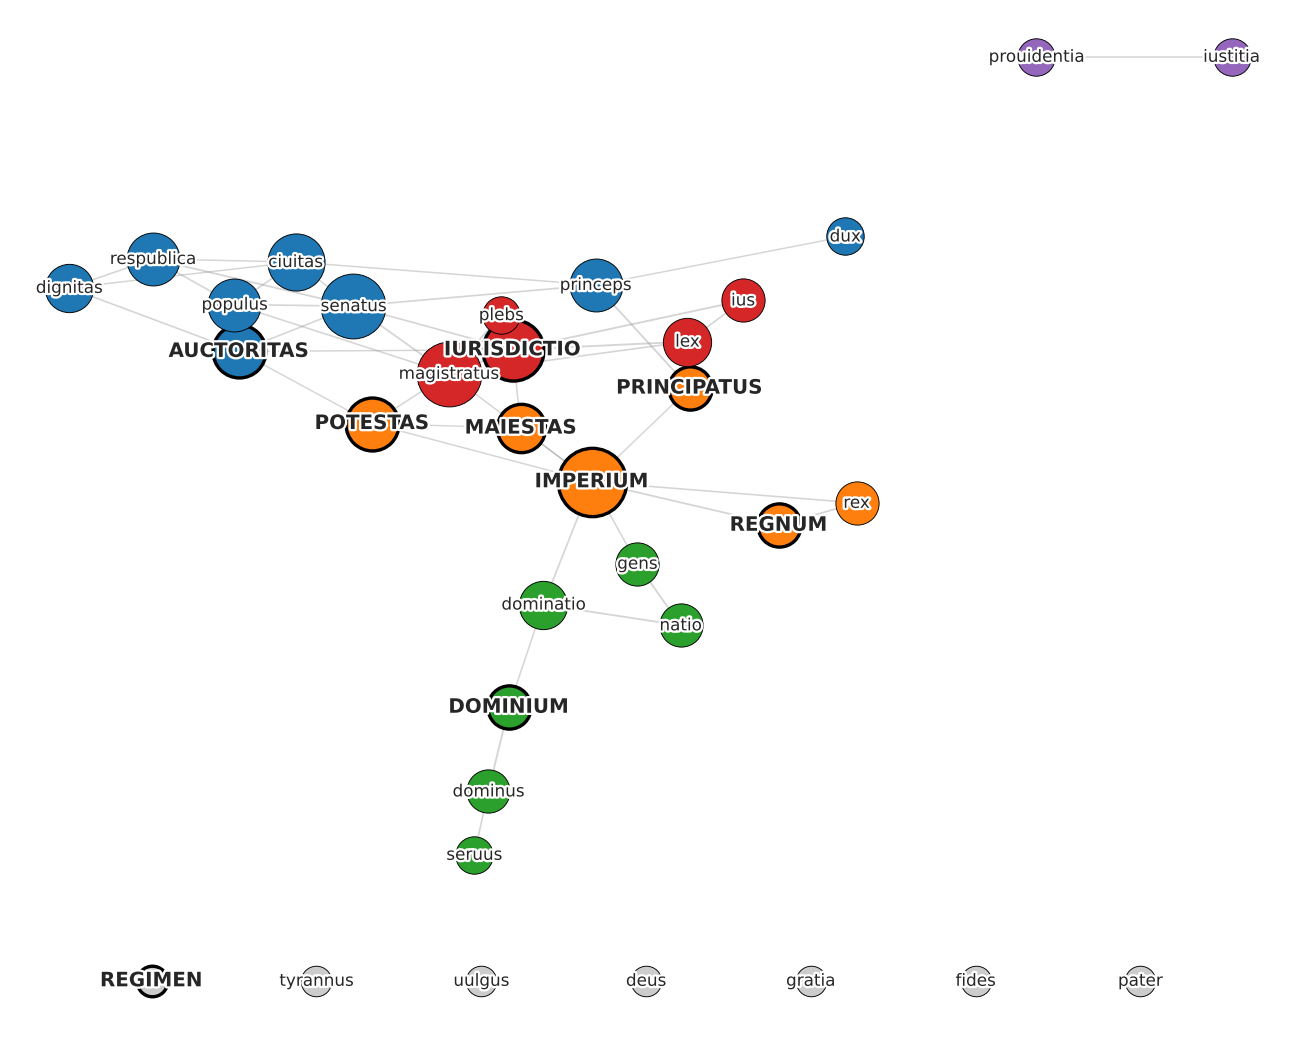

**Рисунок 2. Сеть целевых слов в модели Opera Maiora (Фома Аквинский)**

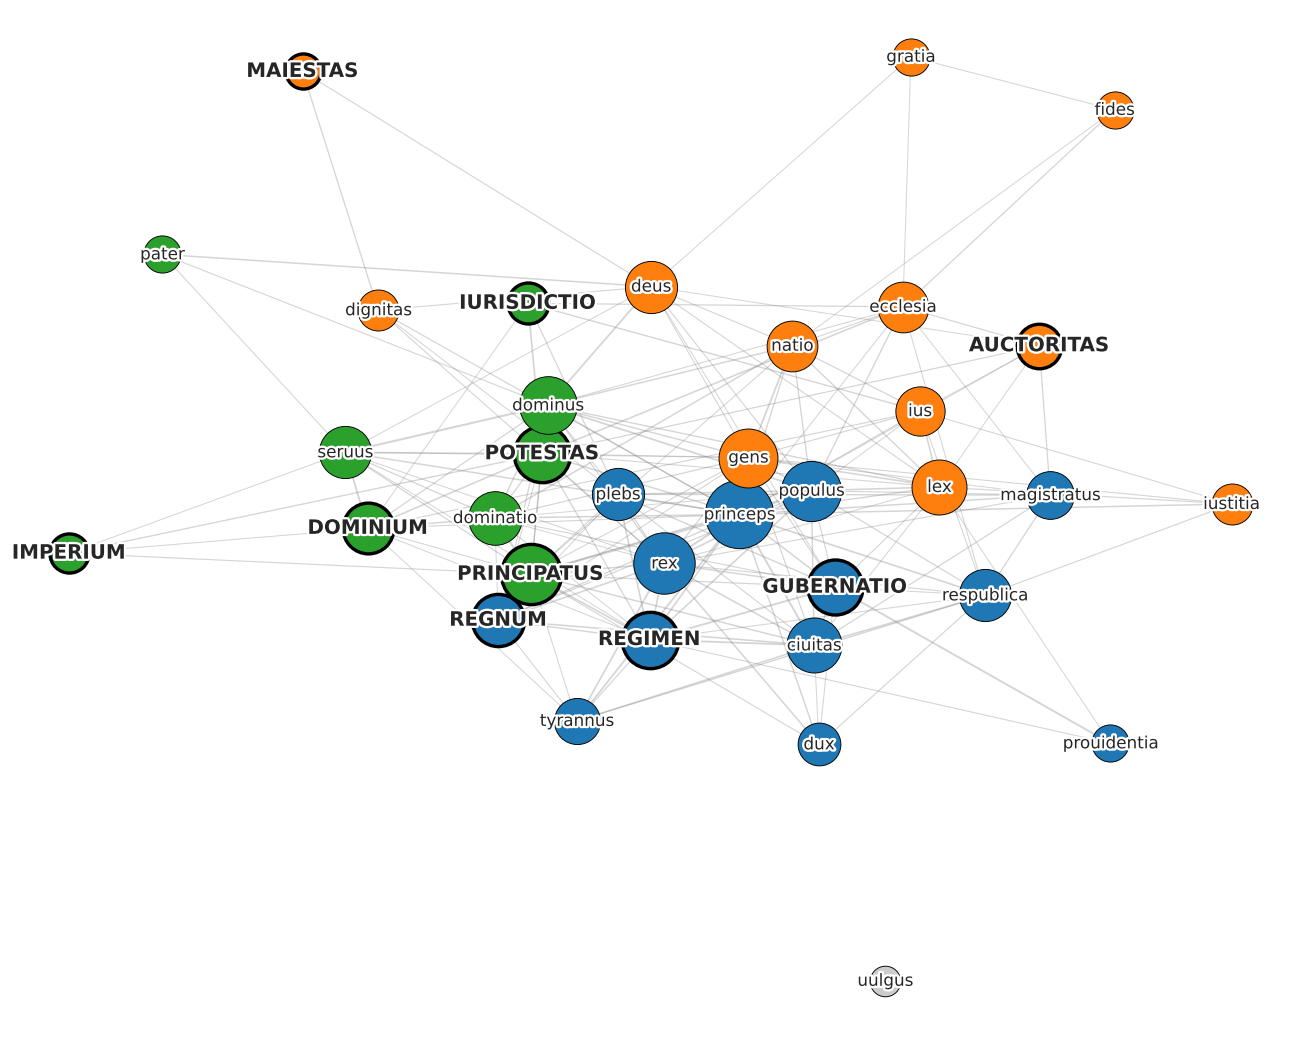

In [24]:
for n, number in zip(MODELS, [1, 2]):
    display(Markdown(f"**Рисунок {number}. Сеть целевых слов в модели {LABEL[n]}**"))
    save_figure(draw_network(NETWORKS[n], PART[n]), f"Fig{number}_network_{n}")

## 7. Центры и мосты (Таблица 5)

Число связей показывает, с каким числом целевых слов данное слово имеет необычно высокое сходство (центры сети). Посредничество показывает, насколько часто кратчайшие пути между другими словами проходят через данное слово (мосты между частями сети).

In [25]:
rows = {}
for n, g in NETWORKS.items():
    degree = pd.Series(dict(g.degree())).sort_values(ascending=False).head(5)
    between = pd.Series(nx.betweenness_centrality(g)).sort_values(ascending=False).head(5)
    rows[f"{LABEL[n]}: число связей"] = [f"{t} ({v})" for t, v in degree.items()]
    rows[f"{LABEL[n]}: посредничество"] = [f"{t} ({v:.2f})" for t, v in between.items()]
display(Markdown("**Таблица 5. Пять слов с наибольшим числом связей и наибольшим посредничеством**"))
display(pd.DataFrame(rows, index=range(1, 6)))
display(Markdown("**Число связей обозначений власти**"))
display(pd.DataFrame({LABEL[n]: {t: g.degree(t) if t in g else "–" for t in CORE_TERMS} for n, g in NETWORKS.items()}))

**Таблица 5. Пять слов с наибольшим числом связей и наибольшим посредничеством**

,Opera Latina: число связей,Opera Latina: посредничество,Opera Maiora (Фома Аквинский): число связей,Opera Maiora (Фома Аквинский): посредничество
1,imperium (8),imperium (0.29),princeps (25),princeps (0.11)
2,magistratus (7),magistratus (0.17),rex (19),deus (0.09)
3,senatus (7),dominatio (0.14),principatus (18),ecclesia (0.06)
4,iurisdictio (6),dominium (0.08),populus (18),dominus (0.04)
5,ciuitas (5),senatus (0.08),gens (17),principatus (0.04)


**Число связей обозначений власти**

,Opera Latina,Opera Maiora (Фома Аквинский)
auctoritas,4,7
potestas,4,15
dominium,2,11
imperium,8,4
regnum,2,12
gubernatio,–,14
regimen,0,15
principatus,2,18
iurisdictio,6,5
maiestas,3,2


## 8. Локальные сети обозначений власти у Фомы (Рисунки 6–9, Приложение)

Для каждого обозначения власти в модели Opera Maiora: шесть ближайших соседей и по четыре ближайших соседа каждого из них. Цвет – кластеры локальной сети (алгоритм Лувена). В статье приведены сети четырёх слов, остальные – в Приложении.

**Рисунок 6. Локальная сеть *regimen* в модели Opera Maiora**

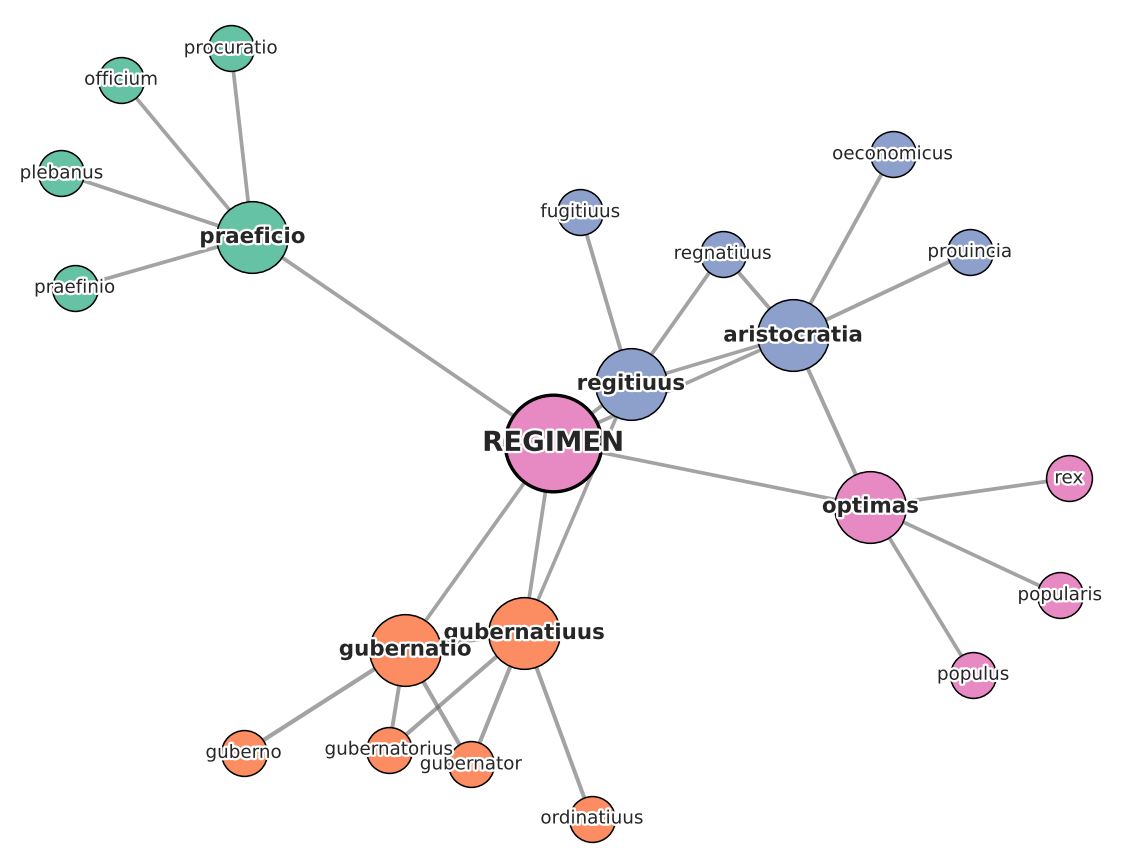

**Рисунок 7. Локальная сеть *gubernatio* в модели Opera Maiora**

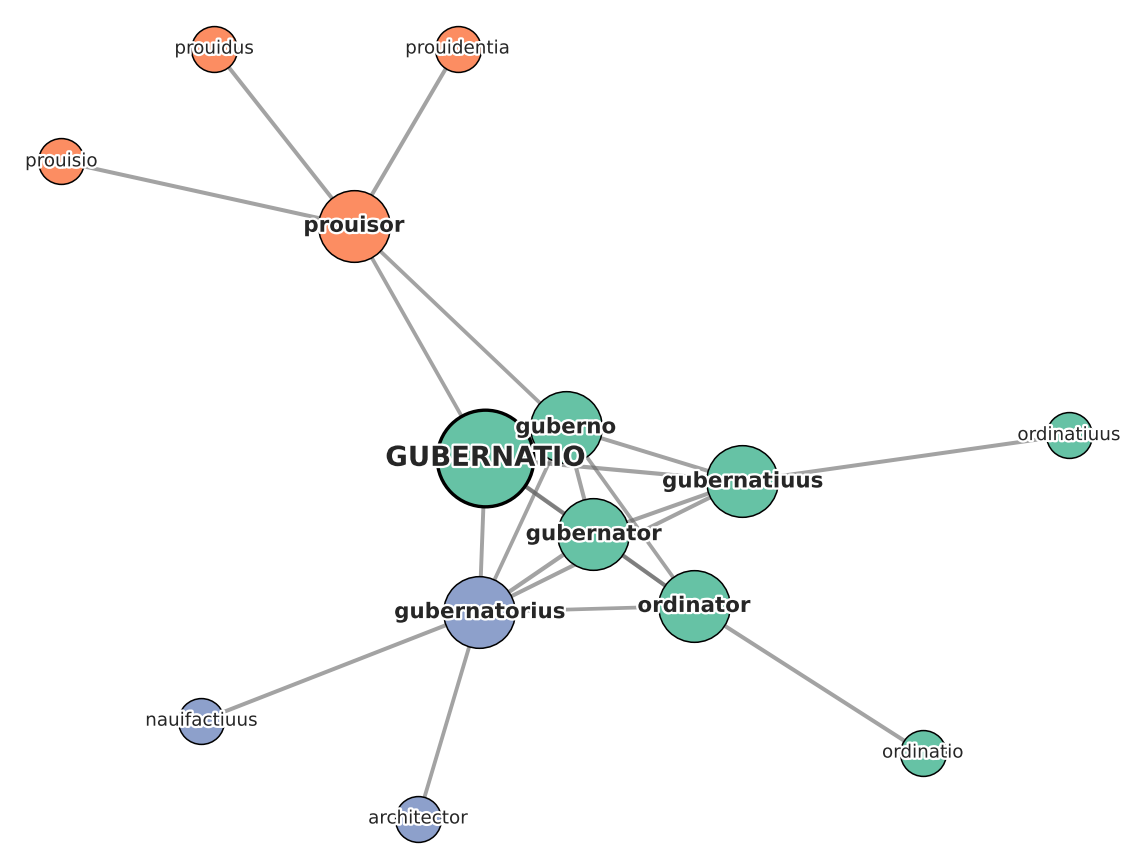

**Рисунок 8. Локальная сеть *potestas* в модели Opera Maiora**

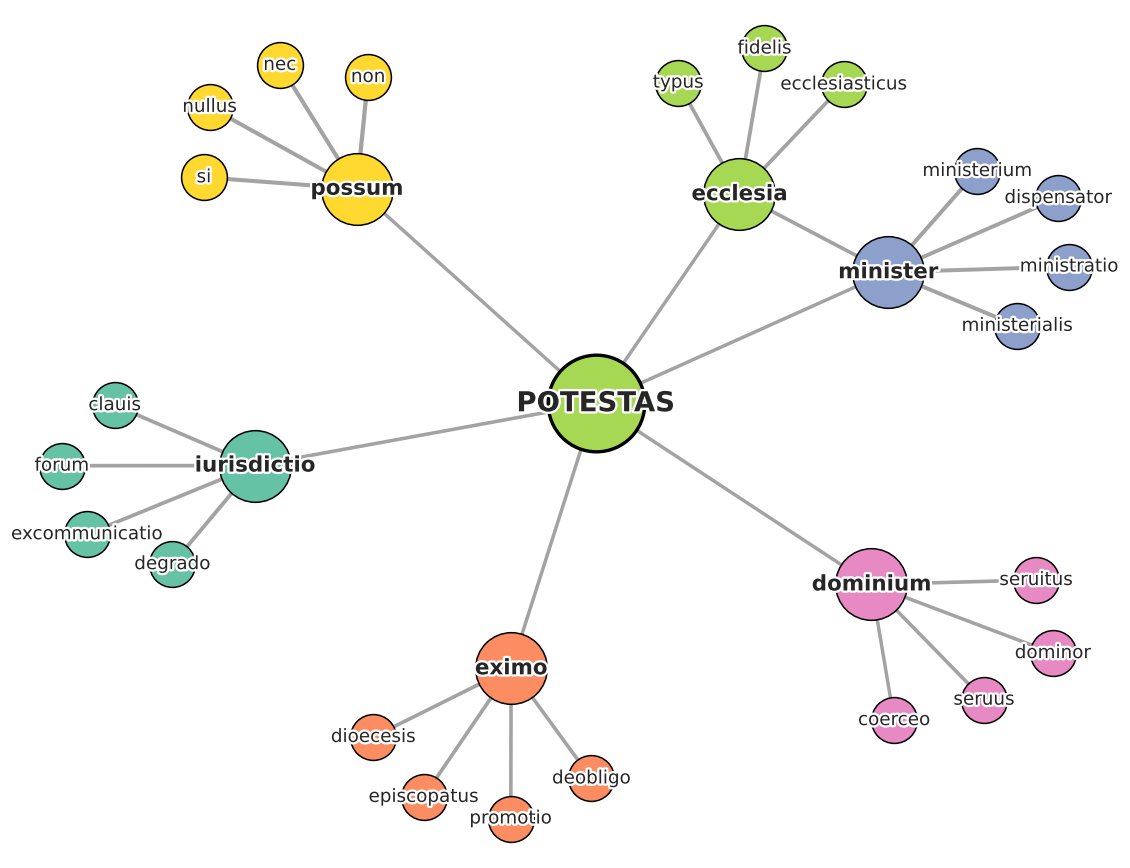

**Рисунок 9. Локальная сеть *auctoritas* в модели Opera Maiora**

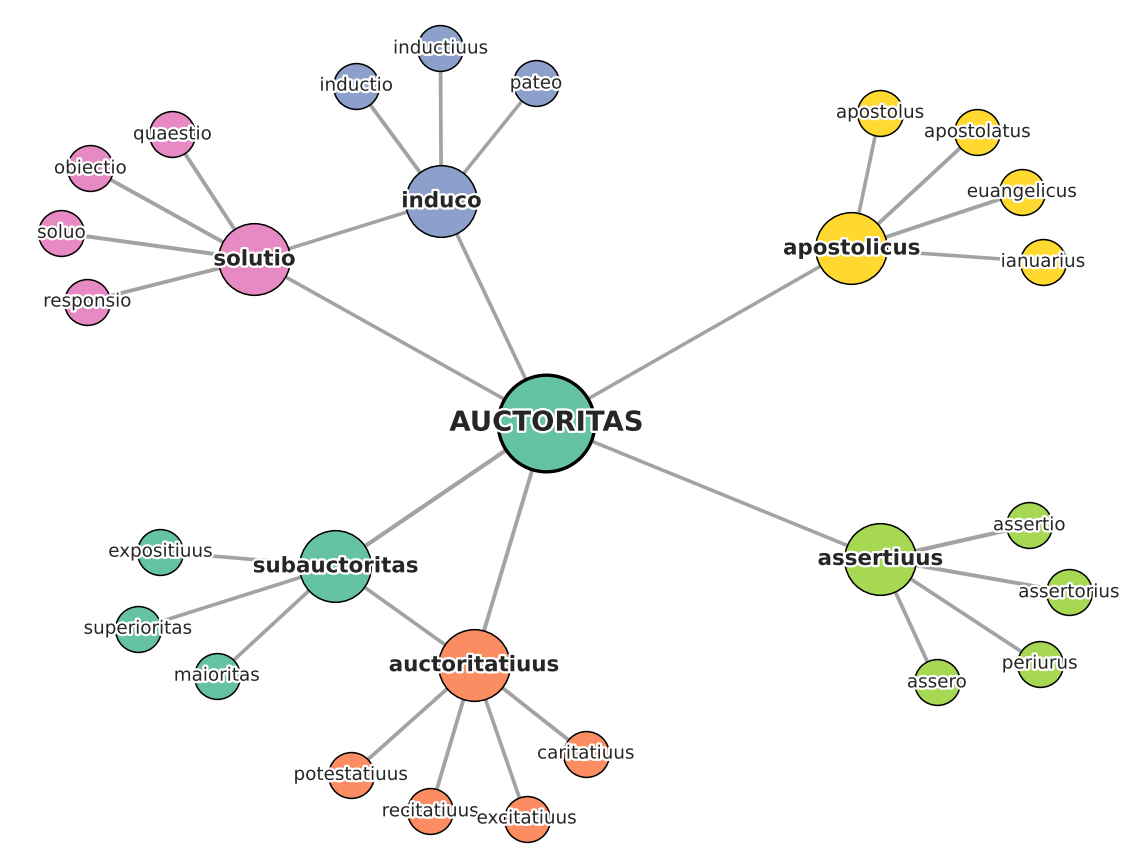

**Рисунок П1. Локальная сеть *dominium* в модели Opera Maiora**

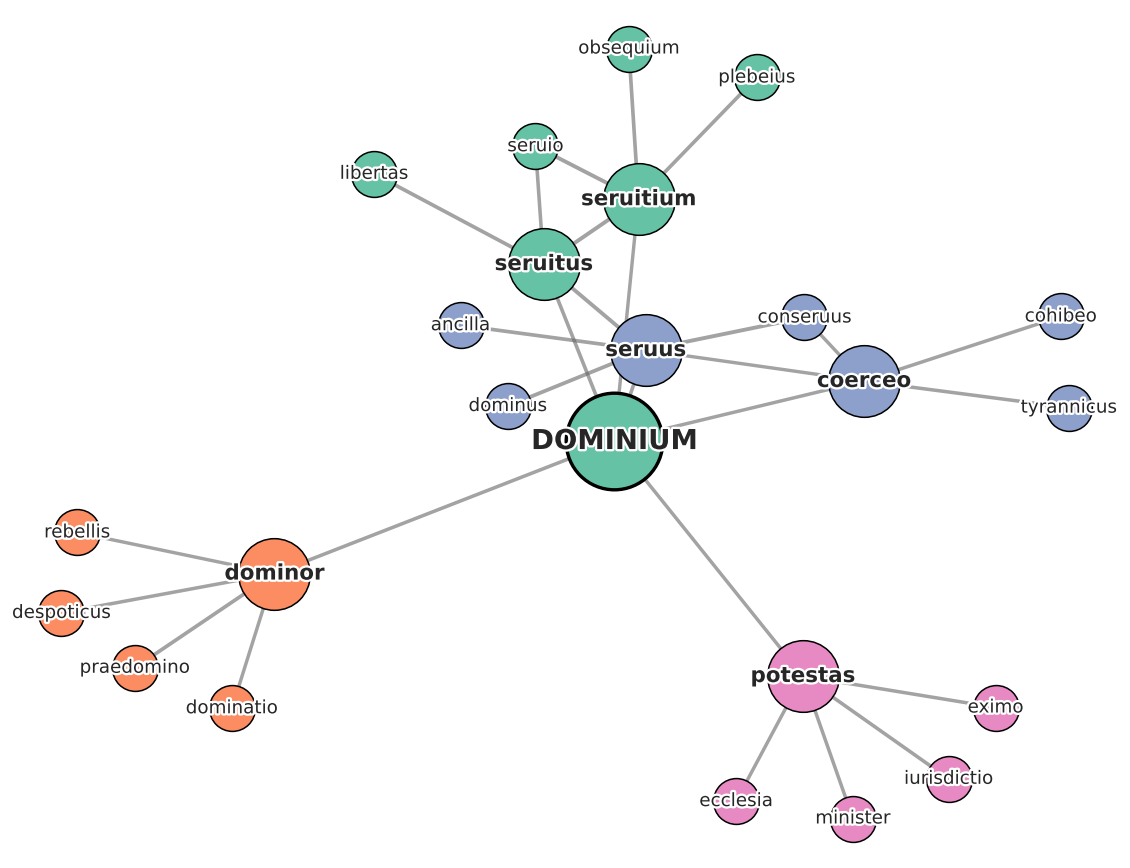

**Рисунок П2. Локальная сеть *imperium* в модели Opera Maiora**

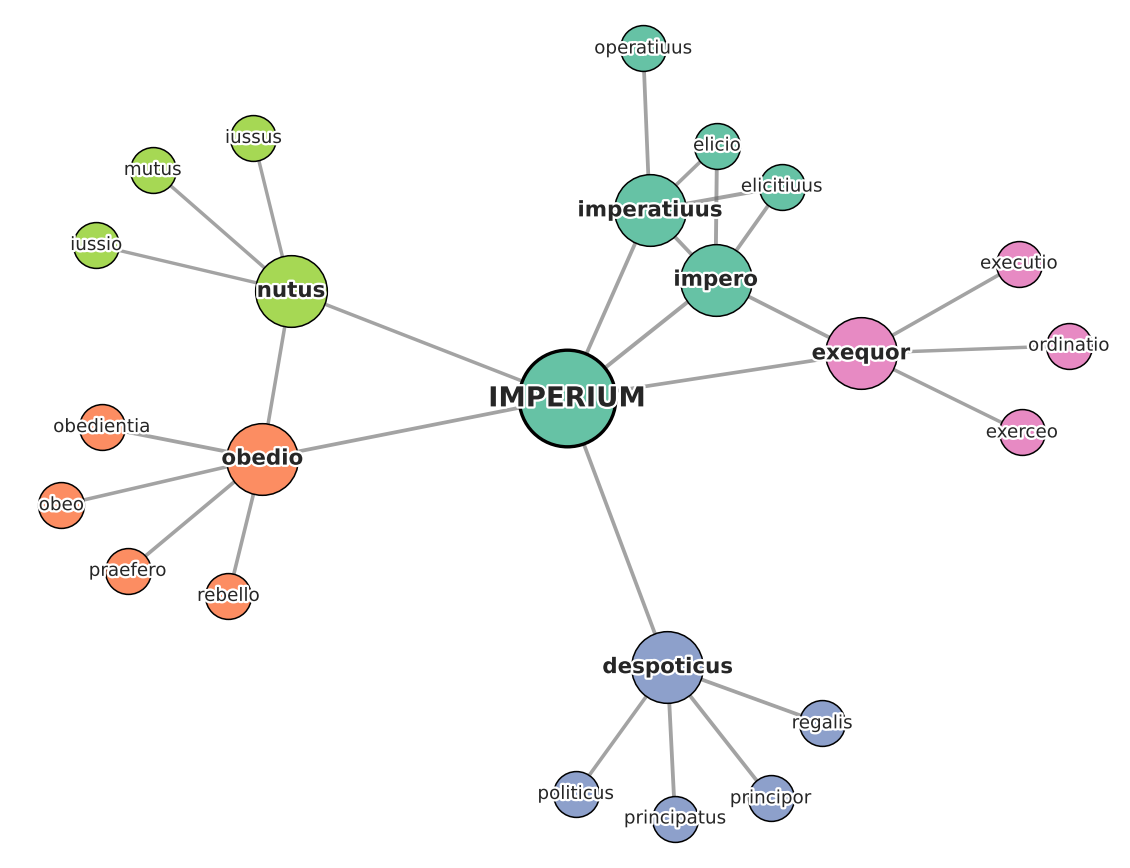

**Рисунок П3. Локальная сеть *regnum* в модели Opera Maiora**

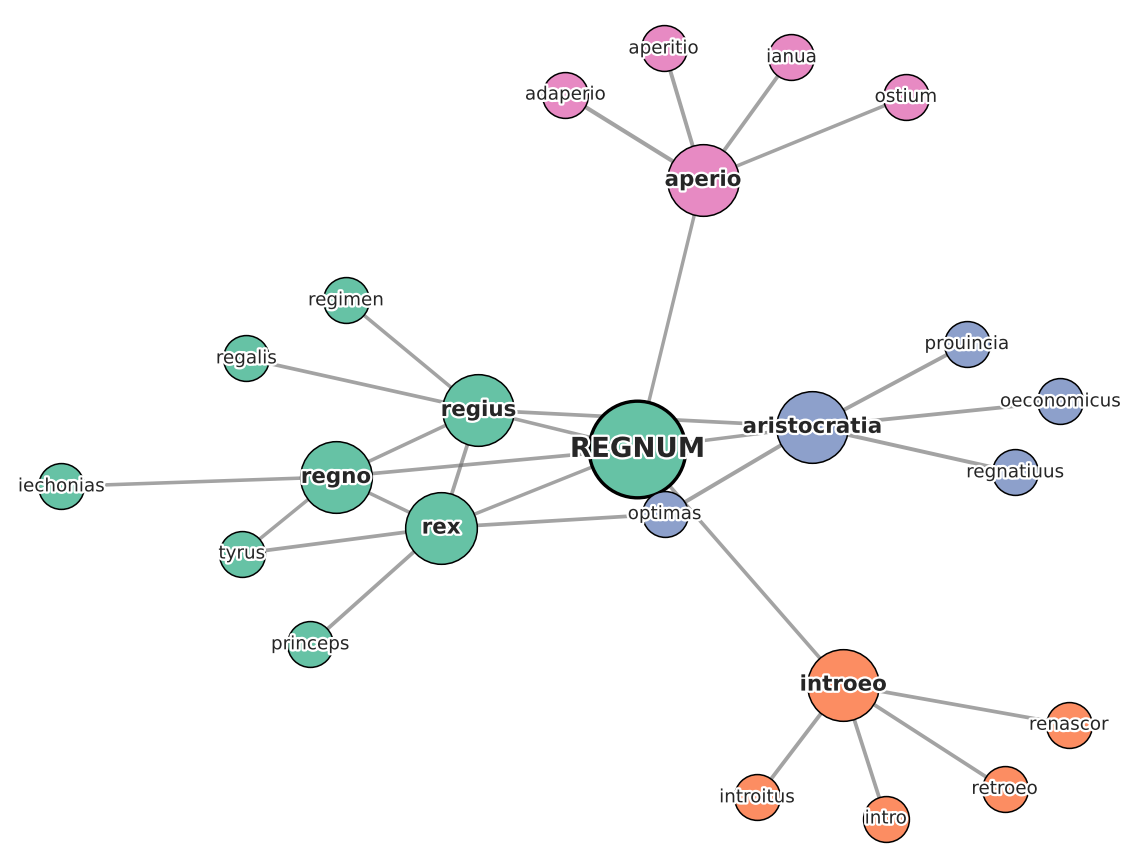

**Рисунок П4. Локальная сеть *principatus* в модели Opera Maiora**

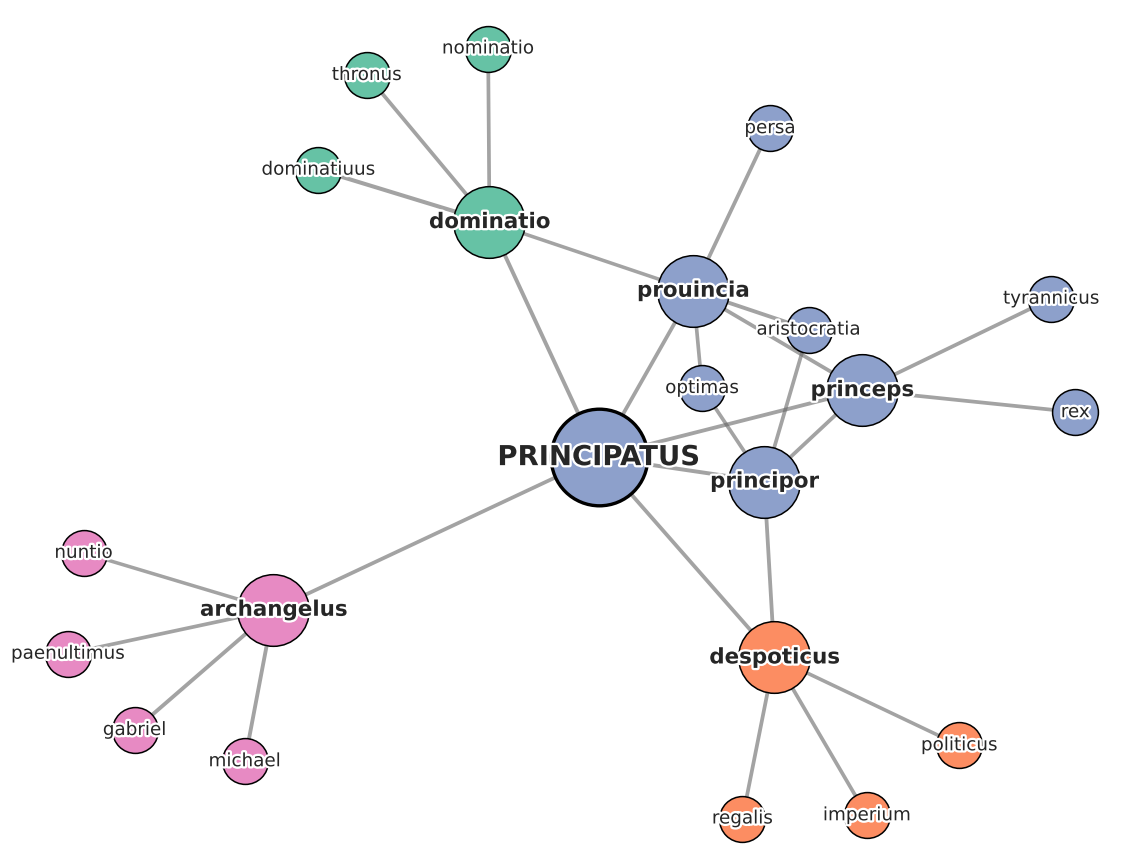

**Рисунок П5. Локальная сеть *iurisdictio* в модели Opera Maiora**

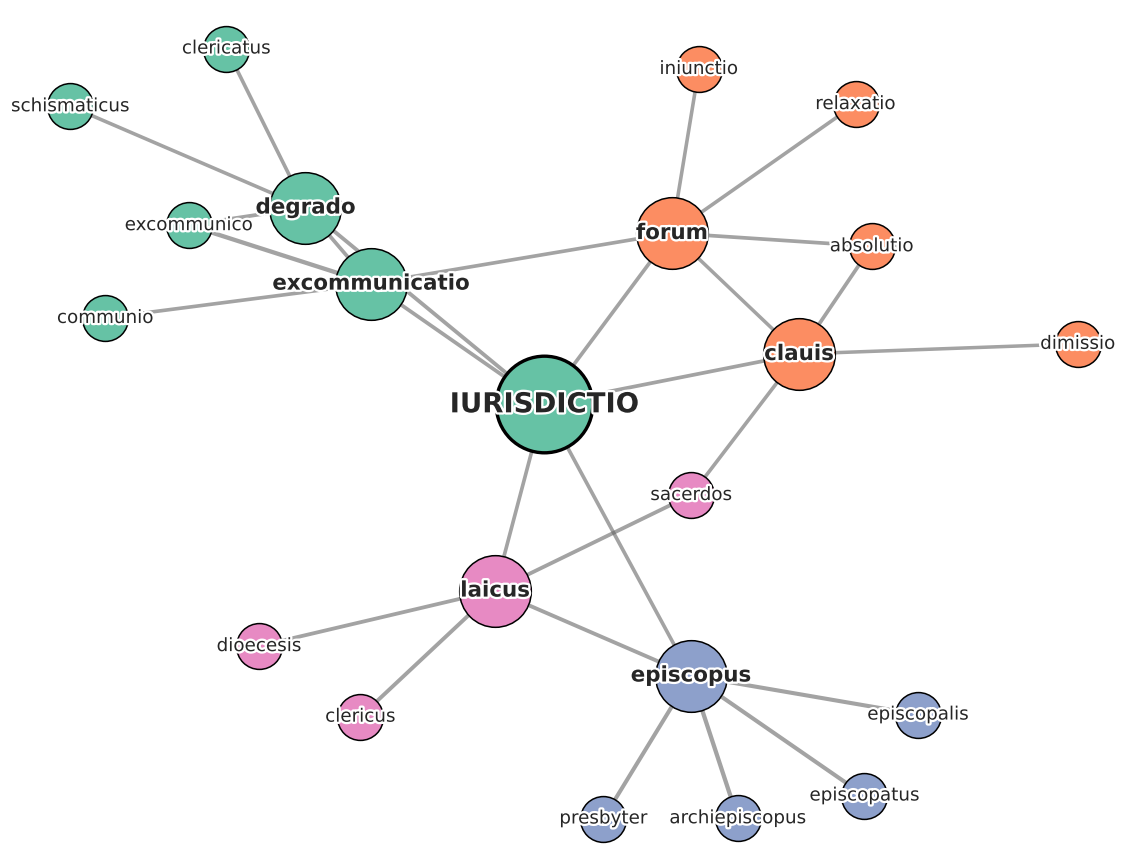

**Рисунок П6. Локальная сеть *maiestas* в модели Opera Maiora**

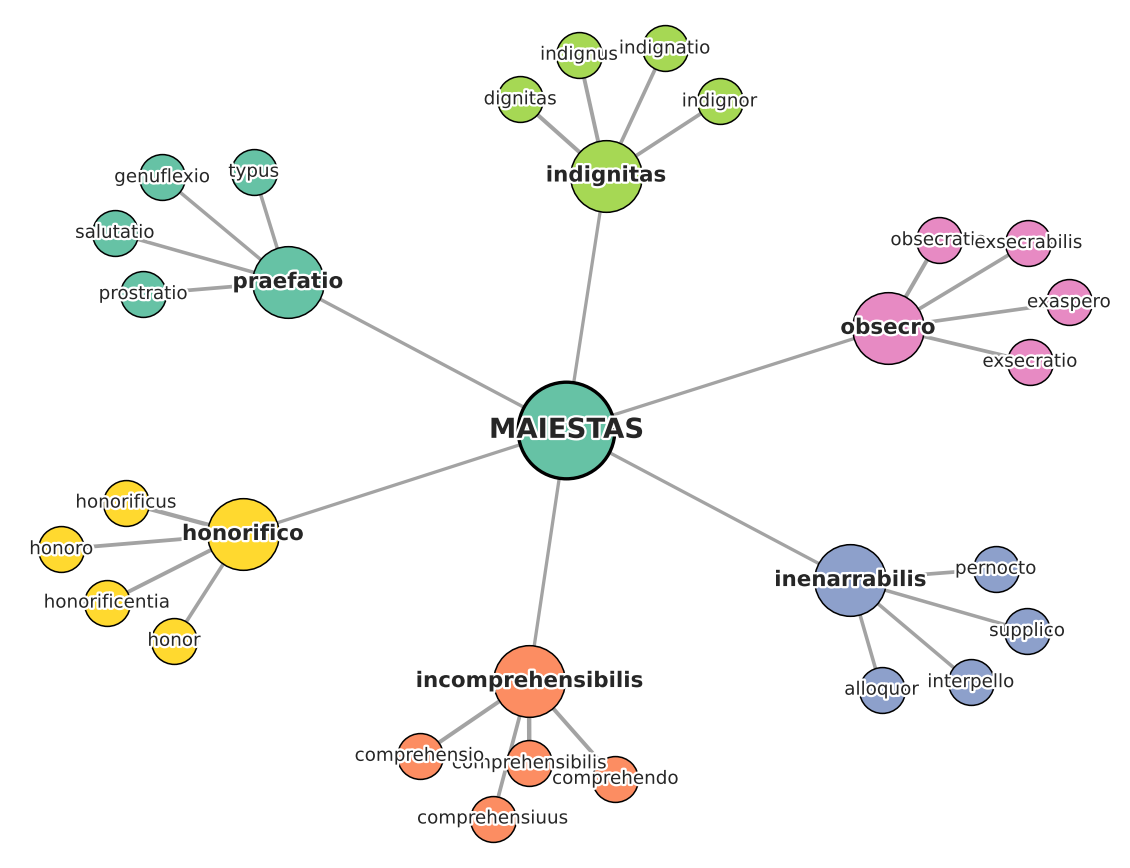

In [26]:
ARTICLE_LOCAL = ["regimen", "gubernatio", "potestas", "auctoritas"]          # Рисунки 6–9 статьи
APPENDIX_LOCAL = [t for t in CORE_TERMS if t not in ARTICLE_LOCAL]            # Рисунки П1–П6 Приложения
for label, terms, prefix, start in [("Рисунок ", ARTICLE_LOCAL, "Fig", 6), ("Рисунок П", APPENDIX_LOCAL, "FigA", 1)]:
    for number, t in enumerate(terms, start=start):
        display(Markdown(f"**{label}{number}. Локальная сеть *{t}* в модели Opera Maiora**"))
        save_figure(draw_local_network(local_network_6_4(MODELS["aquinas"], t)), f"{prefix}{number}_local_{t}")

## 9. Числа, приводимые в статье

In [27]:
facts = []
for n, g in NETWORKS.items():
    b = BACKGROUND[n]
    facts += [(LABEL[n], "Фон: μ / σ / порог μ + 2σ", f"{b['mu']:.3f} / {b['sigma']:.3f} / {THRESHOLD[n]:.3f}"),
              (LABEL[n], "Связей / плотность", f"{g.number_of_edges()} / {nx.density(g):.3f}"),
              (LABEL[n], "Связи potestas ведут в сообщества", ", ".join(map(str, sorted({PART[n][x] for x in g.neighbors('potestas')}))))]
display(pd.DataFrame(facts, columns=["Модель", "Показатель", "Значение"]).set_index(["Модель", "Показатель"]))

Значение
Модель                        Показатель                                              
Opera Latina                  Фон: μ / σ / порог μ + 2σ          0.360 / 0.115 / 0.590
                              Связей / плотность                            43 / 0.077
                              Связи potestas ведут в сообщества                1, 2, 4
Opera Maiora (Фома Аквинский) Фон: μ / σ / порог μ + 2σ          0.279 / 0.108 / 0.496
                              Связей / плотность                           182 / 0.306
                              Связи potestas ведут в сообщества                1, 2, 3